In [1]:
!pip install -q seaborn --upgrade

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 3, Finished, Available, Finished)

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, lit, avg, date_trunc, to_timestamp
from matplotlib.colors import LinearSegmentedColormap

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 4, Finished, Available, Finished)

In [4]:
# ================================== EQUIPMENTS ================================== 
data_equipments = {
    "Equipment": [
        "TRH380", "TRH342", "TRH343", "TRH361", "TRH362", "TRH363", "TRH364",
        "TRH374", "TRH376", "TRH377", "TRH378", "TRH379", "TRH382", "TRH385",
        "TRH386", "TRH390", "TRH391", "TRH392", "TRH394", "TRH395", "TRH396",
        "TRH398", "TRH340", "TRH344", "TRH345", "TRH346", "TRH359", "TRH360",
        "TRH365", "TRH366", "TRH367", "TRH368", "TRH369", "TRH370", "TRH371",
        "TRH372", "TRH373", "TRH375", "TRH381", "TRH383", "TRH384", "TRH387",
        "TRH388", "TRH389", "TRH393", "TRH399", "TRH347"
    ],
    "ClassType": [
        "Cat 793C", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D",
        "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793D", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C",
        "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793C", "Cat 793D"
    ]
}

# Create DataFrame
df_source_equipments = pd.DataFrame(data_equipments)

# Group by 'ClassType' and aggregate equipment into lists
df_equipments = df_source_equipments.groupby("ClassType")["Equipment"].apply(list).reset_index()
df_equipments.columns = ["ClassType", "Equipment"]

# ================================== SENSORS ==================================
data_measurements_list = ["Lt Front Brake Temperature", "Lt Rear Brake Temperature", "Rt Front Brake Temperature", "Rt Rear Brake Temperature"]

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 6, Finished, Available, Finished)

In [12]:
def aggregate_data(df, time_unit):
    """
    Aggregates the data based on the given time unit.

    Parameters:
        df (DataFrame): Filtered PySpark DataFrame.
        time_unit (str): One of ["minute", "hour", "day", "week", "month"].

    Returns:
        DataFrame: Aggregated DataFrame.
    """
    if time_unit == "minute":
        # No aggregation, keep original values
        return df.select("Nombre_Camion", "Categoria", "Nombre_Tag", "Fecha_Hora", "Valor")

    # Define truncation level
    trunc_time = date_trunc(time_unit, col("Fecha_Hora"))

    return (df
        .groupBy("Nombre_Camion", "Categoria", "Nombre_Tag", trunc_time.alias("Fecha_Hora"))
        .agg(avg("Valor").alias("Valor"))
    )

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 14, Finished, Available, Finished)

In [11]:
def execute_heatmap(source_df, df_equipments, start_date, end_date, sort_first_column = False):
    """
    Generates heatmaps based on sensor data filtered by equipment and date range.
    
    This function iterates through a DataFrame of equipment entries, filters a source DataFrame
    according to each equipment's parameters, and converts the filtered Spark DataFrame into a pandas
    DataFrame. It then cleans the data, pivots it to organize sensor values per equipment, and
    generates a heatmap visualization using seaborn's clustermap. Optionally, the pivoted DataFrame 
    can be sorted by its first column, and the clustering behavior for the heatmap is adjusted accordingly.
    
    Parameters:
    - source_df: Spark DataFrame containing raw sensor data.
    - df_equipments: DataFrame containing equipment details with columns such as 'ClassType' and 'Equipment'.
    - start_date: A string representing the start of the time range in "YYYY-MM-DD HH:MM:SS" format.
    - end_date: A string representing the end of the time range in "YYYY-MM-DD HH:MM:SS" format.
    - sort_first_column: Boolean flag that if True, sorts the pivoted DataFrame by its first column 
                         and disables row and column clustering.
                         
    The function displays the heatmap and saves it as a JPEG image with a timestamped filename.
    """
    
    # Generate a timestamp (e.g., "2025-03-19_14-30-45") for saving the image file
    timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    
    # Convert the provided start_date and end_date strings into datetime objects
    start_date_dt = datetime.strptime(start_date, "%Y-%m-%d %H:%M:%S")
    end_date_dt = datetime.strptime(end_date, "%Y-%m-%d %H:%M:%S")
    
    # Set clustering flag to True by default; may be disabled if sorting is applied
    cluster_on = True
    
    # Loop through each equipment row in the equipments DataFrame
    for index, row_equipment in df_equipments.iterrows():
        print(f"Fleet: {row_equipment['ClassType']} | Equipment: {row_equipment['Equipment']}")
        
        # Filter source_df based on the current equipment, sensor list, and date range.
        # Note: data_measurements_list should be defined in the outer scope.
        df_filtered = source_df.filter(
            (col("Nombre_Camion").isin(row_equipment["Equipment"])) & 
            (col("Nombre_Tag").isin(data_measurements_list)) & 
            (col("Fecha_Hora").between(lit(start_date_dt), lit(end_date_dt))) 
        )
        
        # Replace any missing (NaN) values with zeros and ensure "Valor" column is of type double
        df_filtered = df_filtered.na.fill(0)
        df_filtered = df_filtered.withColumn("Valor", col("Valor").cast("double"))
        
        # Convert the Spark DataFrame to a pandas DataFrame for further processing and visualization
        source_pandas_df = df_filtered.toPandas()
        
        # Select only the relevant columns and rename them for clarity
        dataset = source_pandas_df[["Nombre_Camion", "Nombre_Tag", "Valor"]]
        dataset.columns = ["Equipment", "Sensor", "Value"]
        
        # Remove NaN values (if any remain) and filter out sensor values outside the expected range (0 to 100)
        dataset = dataset[(dataset["Value"] >= 0) & (dataset["Value"] <= 100)]
        
        # Count the number of rows after filtering and display the count
        row_count = len(dataset)
        print(f"Total rows: {row_count}")
        
        if row_count > 0:
            # Pivot the dataset so that each row represents an equipment and each column a sensor;
            # The cell values are the mean of the "Value" column.
            df = dataset.pivot_table(index="Equipment", columns="Sensor", values="Value", aggfunc="mean")
            
            # Create a copy of the pivoted DataFrame for potential display purposes
            table_showing = df.copy()
            table_showing.reset_index(inplace=True)
            # Optionally, display the table (e.g., in a notebook)
            # display(table_showing)
            
            # Replace any NaN values in the pivoted DataFrame with zeros
            df[np.isnan(df)] = 0
            
            # If requested, sort the pivoted DataFrame by its first column and disable clustering
            if sort_first_column:
                df = df.sort_values(by=df.columns[0], ascending=True)
                cluster_on = False
                
            # Only generate a heatmap if there's more than one row to display
            if len(df) > 1:
                # Adjust figure size as necessary
                plt.figure(figsize=(40, 32))
                
                # Generate a clustermap heatmap with annotations, using the 'viridis_r' color map.
                # Clustering is applied based on the 'cluster_on' flag.
                g = sns.clustermap(df, annot=True, cmap='viridis_r', fmt=".2f", row_cluster=cluster_on, col_cluster=cluster_on)
                
                # Set a descriptive title including the fleet class and date range
                plt.suptitle(f"Heatmap | {row_equipment['ClassType']} ({start_date_dt.date()} - {end_date_dt.date()})", 
                             fontsize=14, fontweight="bold", x=0.85, y=0.98)
                
                # Label the heatmap axes
                g.ax_heatmap.set_xlabel("Features")
                g.ax_heatmap.set_ylabel("Features")
                
                # Invert y-axis for one of the axes (depending on the clustermap configuration)
                g.fig.axes[2].invert_yaxis()
                
                # Display the heatmap plot
                plt.show()
                
                # Save the heatmap as a JPEG image with a unique timestamp in the filename
                plt.savefig(f"/lakehouse/default/Files/Images/Heatmap_{row_equipment['ClassType']}_{timestamp}.jpeg", dpi=400)

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 13, Finished, Available, Finished)

# Call data from source

In [13]:
source_df = spark.table("sensores_camiones")
source_df = source_df.withColumn("Fecha_Hora", to_timestamp(col("Fecha_Hora"), "yyyy-MM-dd HH:mm:ss"))
source_df = source_df.withColumn("Valor", col("Valor").cast("double"))

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 15, Finished, Available, Finished)

# This year 2025 until now

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 16, Finished, Available, Finished)

Fleet: Cat 793C | Equipment: ['TRH380', 'TRH374', 'TRH376', 'TRH377', 'TRH378', 'TRH379', 'TRH382', 'TRH385', 'TRH386', 'TRH390', 'TRH391', 'TRH392', 'TRH394', 'TRH395', 'TRH396', 'TRH398', 'TRH340', 'TRH370', 'TRH371', 'TRH372', 'TRH373', 'TRH375', 'TRH381', 'TRH383', 'TRH384', 'TRH387', 'TRH388', 'TRH389', 'TRH393', 'TRH399']
Total rows: 200089


<Figure size 4000x3200 with 0 Axes>

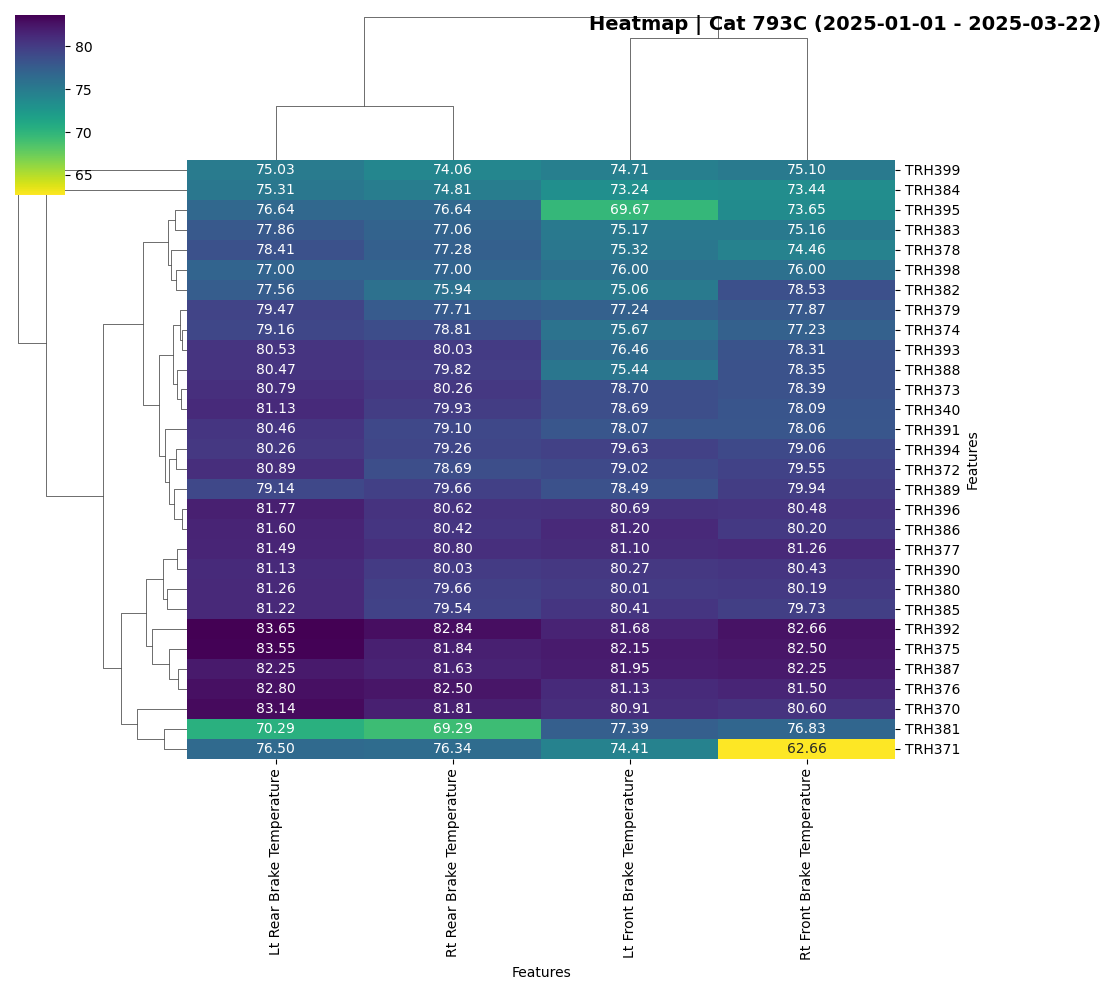

Fleet: Cat 793D | Equipment: ['TRH342', 'TRH343', 'TRH361', 'TRH362', 'TRH363', 'TRH364', 'TRH344', 'TRH345', 'TRH346', 'TRH359', 'TRH360', 'TRH365', 'TRH366', 'TRH367', 'TRH368', 'TRH369', 'TRH347']
Total rows: 113115


<Figure size 640x480 with 0 Axes>

<Figure size 4000x3200 with 0 Axes>

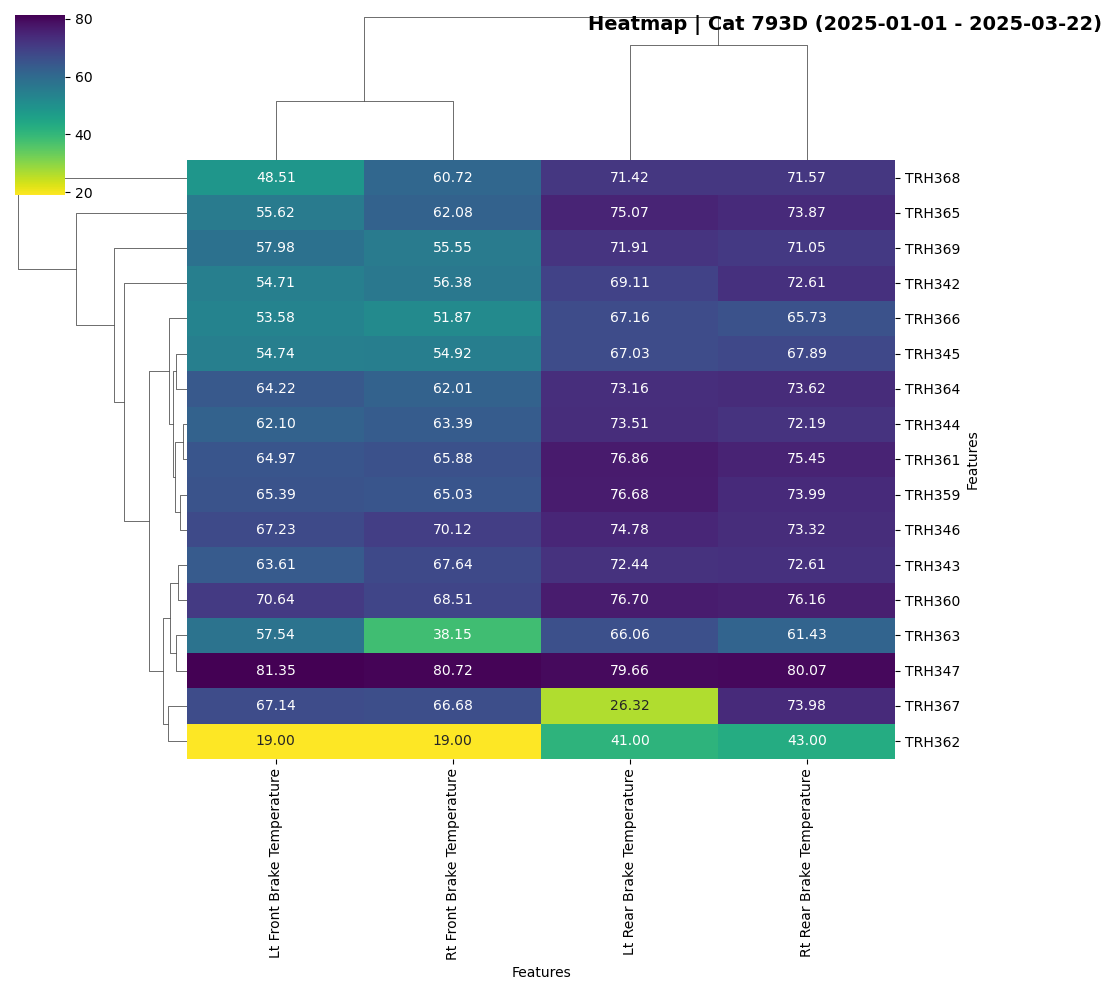

<Figure size 640x480 with 0 Axes>

In [14]:
""" Example:
minute_source_df = aggregate_data(source_df, "minute") # Original data
hour_source_df = aggregate_data(source_df, "hour")
day_source_df = aggregate_data(source_df, "day")
week_source_df = aggregate_data(source_df, "week")
month_source_df = aggregate_data(source_df, "month")
"""
start_date = "2025-01-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
hour_source_df = aggregate_data(source_df, "hour")
execute_heatmap(
    source_df=hour_source_df,
    df_equipments=df_equipments, 
    start_date=start_date, 
    end_date=end_date, 
    sort_first_column=False
)

# 1. De Diciembe a marzo

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 11, Finished, Available, Finished)

Fleet: Cat 793C | Equipment: ['TRH380', 'TRH374', 'TRH376', 'TRH377', 'TRH378', 'TRH379', 'TRH382', 'TRH385', 'TRH386', 'TRH390', 'TRH391', 'TRH392', 'TRH394', 'TRH395', 'TRH396', 'TRH398', 'TRH340', 'TRH370', 'TRH371', 'TRH372', 'TRH373', 'TRH375', 'TRH381', 'TRH383', 'TRH384', 'TRH387', 'TRH388', 'TRH389', 'TRH393', 'TRH399']
Total rows: 288288


<Figure size 4000x3200 with 0 Axes>

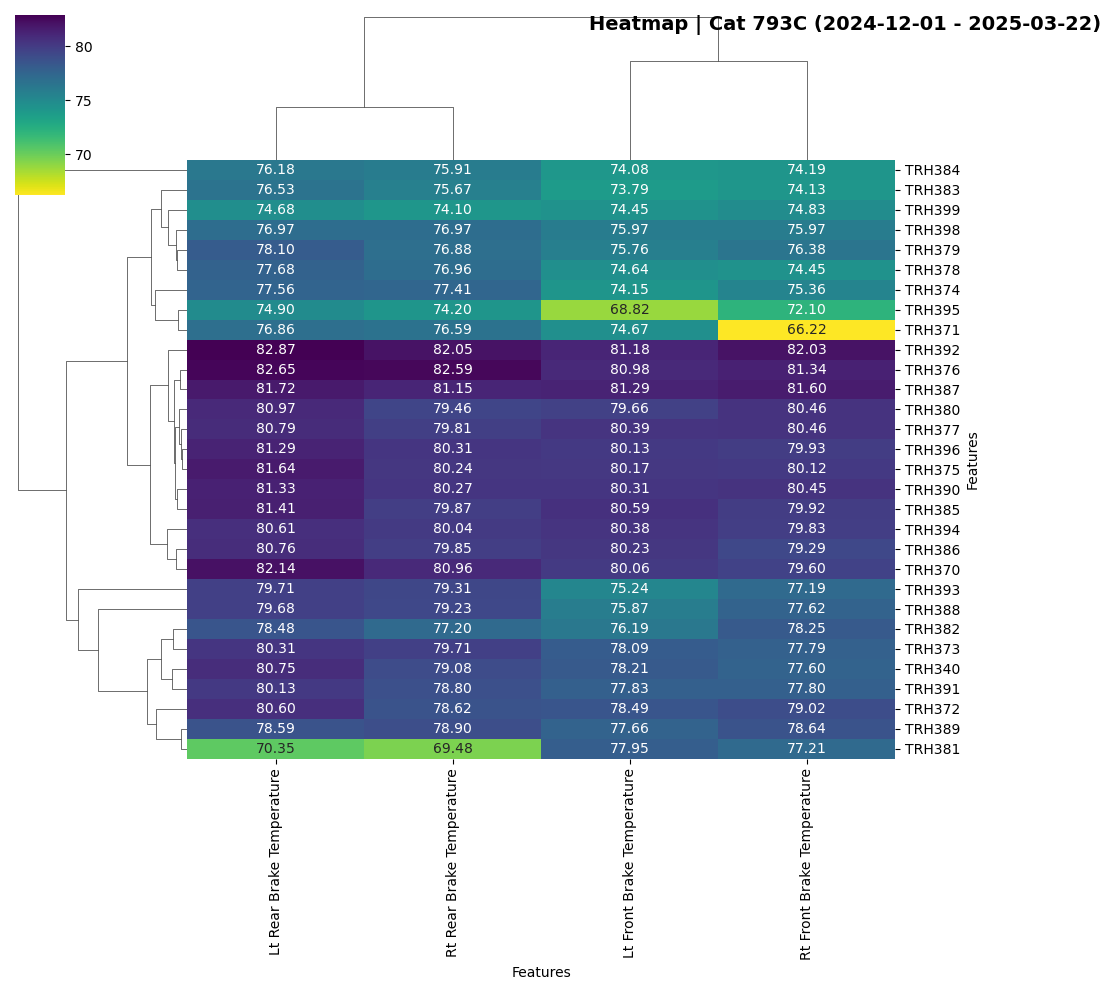

Fleet: Cat 793D | Equipment: ['TRH342', 'TRH343', 'TRH361', 'TRH362', 'TRH363', 'TRH364', 'TRH344', 'TRH345', 'TRH346', 'TRH359', 'TRH360', 'TRH365', 'TRH366', 'TRH367', 'TRH368', 'TRH369', 'TRH347']
Total rows: 162837


<Figure size 640x480 with 0 Axes>

<Figure size 4000x3200 with 0 Axes>

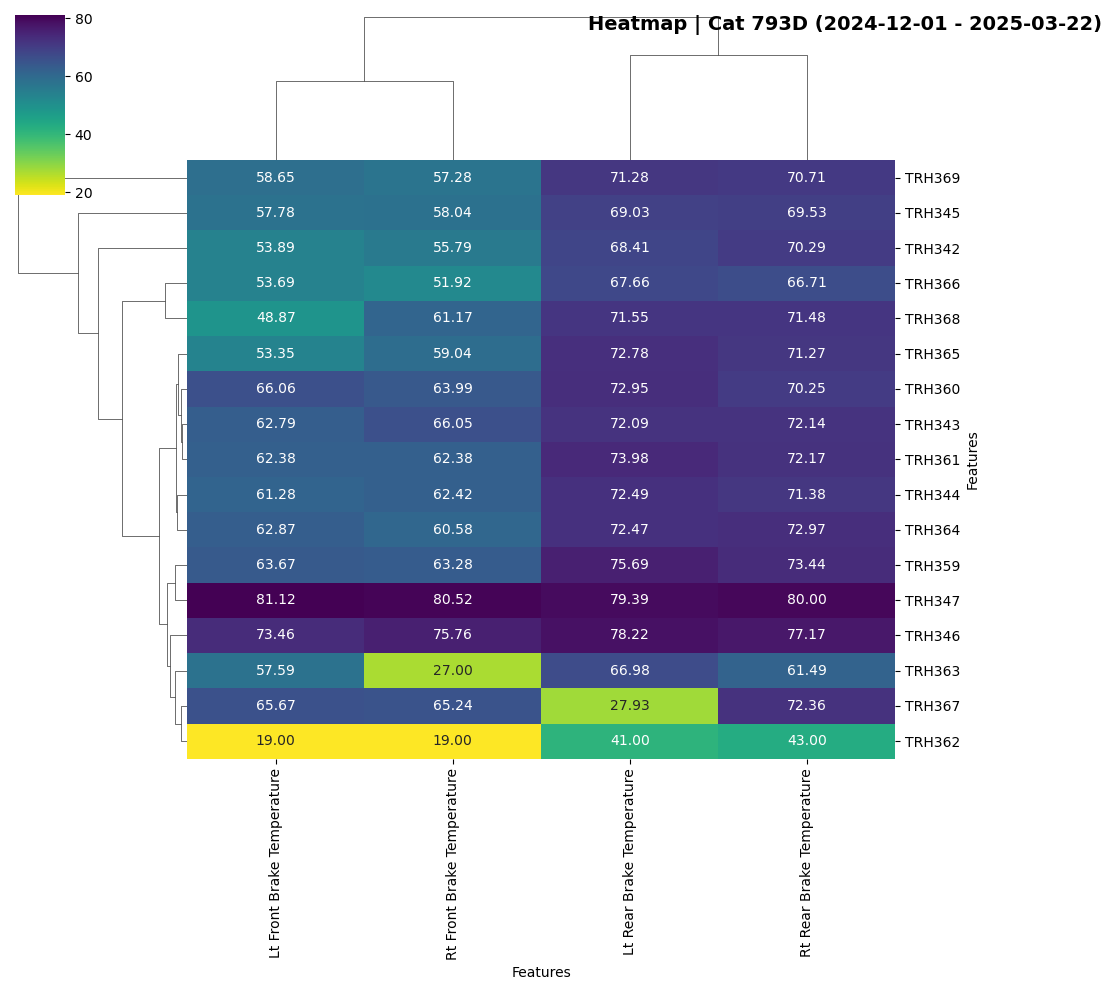

<Figure size 640x480 with 0 Axes>

In [9]:
start_date = "2024-12-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
hour_source_df = aggregate_data(source_df, "hour")
execute_heatmap(
    source_df=hour_source_df,
    df_equipments=df_equipments, 
    start_date=start_date, 
    end_date=end_date, 
    sort_first_column=False
)

# 2. Desde enero 2024 hasta hoy

StatementMeta(, ca9e4cf3-729d-49a7-bd10-aa43ac7e7055, 12, Finished, Available, Finished)

Fleet: Cat 793C | Equipment: ['TRH380', 'TRH374', 'TRH376', 'TRH377', 'TRH378', 'TRH379', 'TRH382', 'TRH385', 'TRH386', 'TRH390', 'TRH391', 'TRH392', 'TRH394', 'TRH395', 'TRH396', 'TRH398', 'TRH340', 'TRH370', 'TRH371', 'TRH372', 'TRH373', 'TRH375', 'TRH381', 'TRH383', 'TRH384', 'TRH387', 'TRH388', 'TRH389', 'TRH393', 'TRH399']
Total rows: 1238451


<Figure size 4000x3200 with 0 Axes>

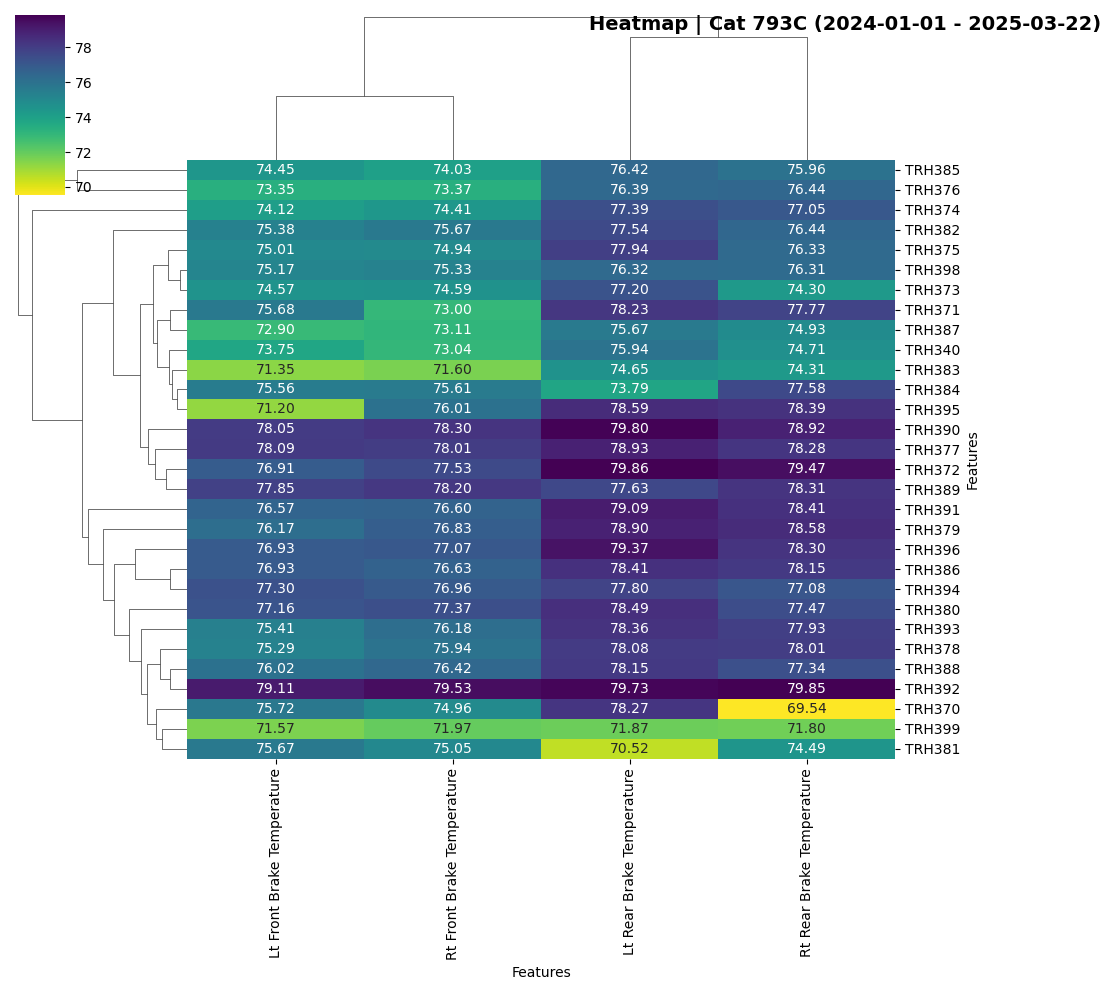

Fleet: Cat 793D | Equipment: ['TRH342', 'TRH343', 'TRH361', 'TRH362', 'TRH363', 'TRH364', 'TRH344', 'TRH345', 'TRH346', 'TRH359', 'TRH360', 'TRH365', 'TRH366', 'TRH367', 'TRH368', 'TRH369', 'TRH347']
Total rows: 690091


<Figure size 640x480 with 0 Axes>

<Figure size 4000x3200 with 0 Axes>

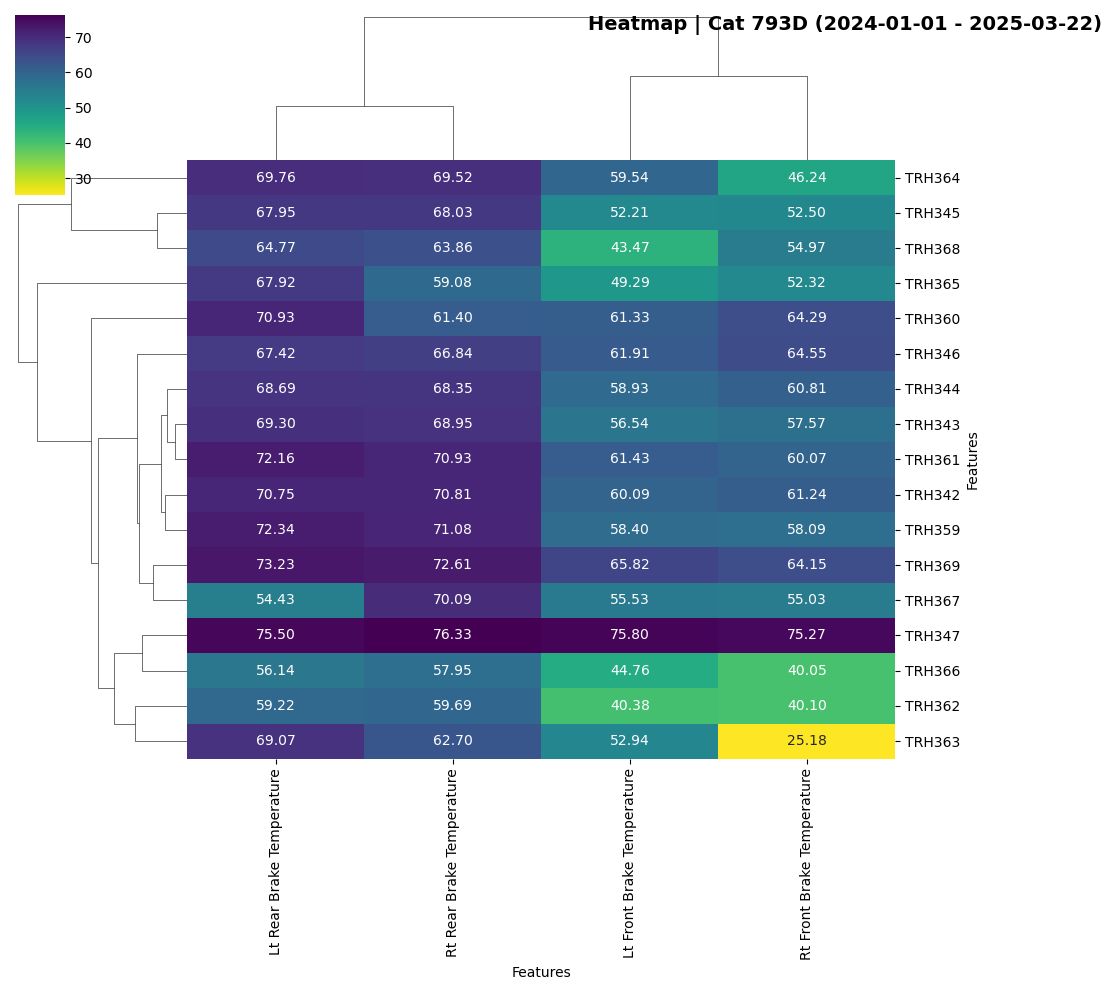

<Figure size 640x480 with 0 Axes>

In [10]:
start_date = "2024-01-01 00:00:00"
end_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
hour_source_df = aggregate_data(source_df, "hour")
execute_heatmap(
    source_df=hour_source_df,
    df_equipments=df_equipments, 
    start_date=start_date, 
    end_date=end_date, 
    sort_first_column=False
)

# Test Code

In [65]:
test_start_date = "2025-01-01 00:00:00"
test_end_date = "2025-03-22 00:00:00"
source_df = spark.table("sensores_camiones")
df_filtered = source_df.filter(
    (col("Nombre_Camion").isin(['TRH342', 'TRH343', 'TRH361', 'TRH362', 'TRH363', 'TRH364', 'TRH344', 'TRH345', 'TRH346', 'TRH359', 'TRH360', 'TRH365', 'TRH366', 'TRH367', 'TRH368', 'TRH369', 'TRH347'])) & 
    (col("Nombre_Tag").isin(["Lt Front Brake Temperature","Lt Rear Brake Temperature","Rt Front Brake Temperature","Rt Rear Brake Temperature"])) & 
    (col("Fecha_Hora").between(test_start_date, test_end_date)) 
)
source_pandas_df = df_filtered.toPandas()

StatementMeta(, 01f79689-2b6f-49e3-a62f-99fa2265734c, 67, Finished, Available, Finished)

In [66]:
dataset = source_pandas_df[["Nombre_Camion", "Nombre_Tag", "Valor"]]
dataset.columns = ["Equipment", "Sensor", "Value"]
dataset = dataset.dropna(subset=["Value"])
dataset = dataset[(dataset["Value"] >= 0) & (dataset["Value"] <= 100)]
test_df = dataset.pivot_table(index="Equipment", columns="Sensor", values="Value", aggfunc="mean")
#df.reset_index(inplace=True)

StatementMeta(, 01f79689-2b6f-49e3-a62f-99fa2265734c, 68, Finished, Available, Finished)

StatementMeta(, 01f79689-2b6f-49e3-a62f-99fa2265734c, 113, Finished, Available, Finished)

<Figure size 4000x3200 with 0 Axes>

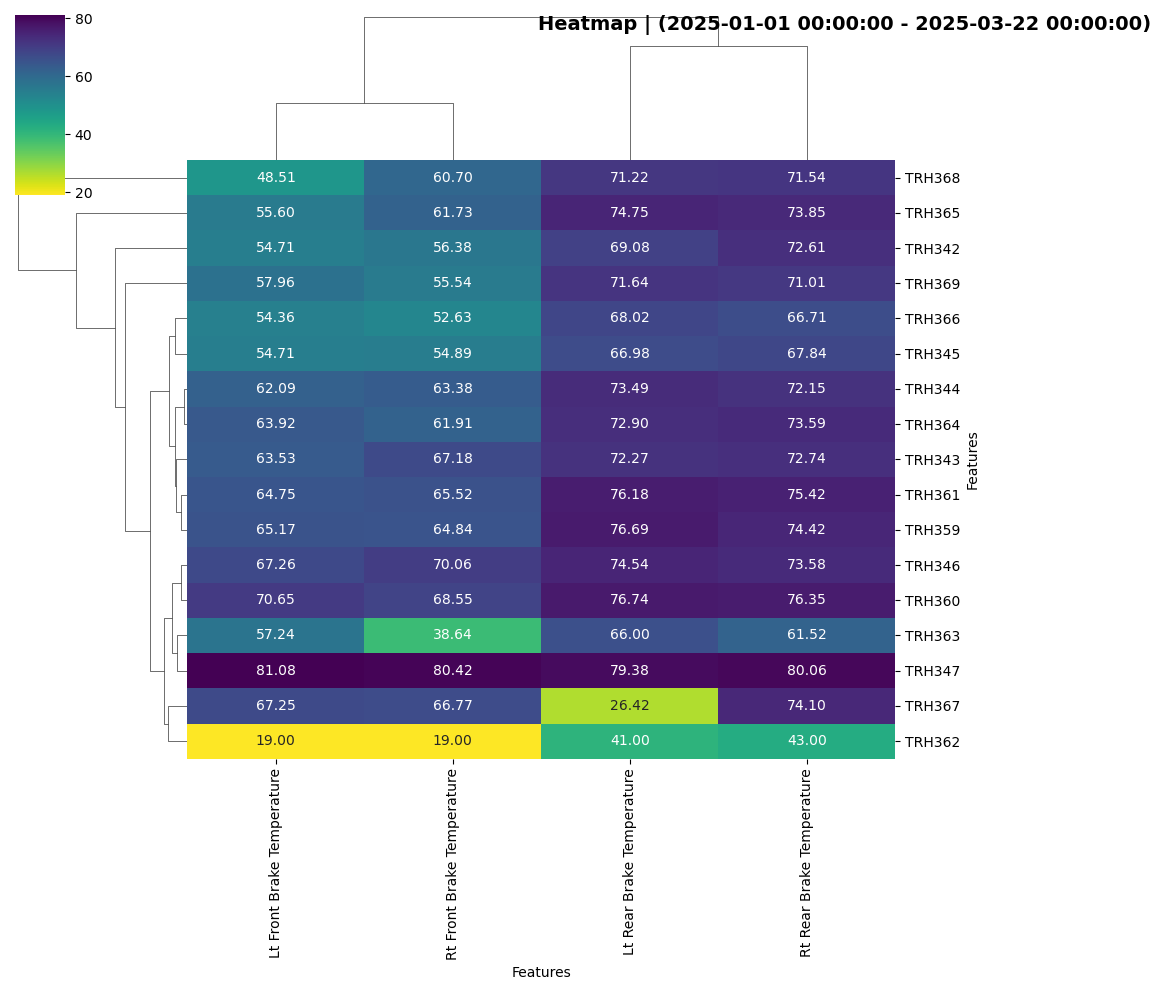

In [111]:
plt.figure(figsize=(40, 32))  # Adjust the figure size as needed
df_sorted = test_df.sort_values(by=test_df.columns[0], ascending=False)
custom_cmap = LinearSegmentedColormap.from_list("custom_cmap", ["#ffeda0", "#fc973f", "#f03b21"], N=256)
g = sns.clustermap(df_sorted, annot=True, cmap="viridis_r", fmt=".2f")
plt.suptitle(f"Heatmap | ({test_start_date} - {test_end_date})", fontsize=14, fontweight="bold", x=0.85, y=0.98)
g.ax_heatmap.set_xlabel("Features")
g.ax_heatmap.set_ylabel("Features")
g.fig.axes[2].invert_yaxis()
#g.fig.axes[2].yaxis.set_inverted(True)
plt.show()

### Delete All Files | Run if need to clean the folder

In [11]:
import glob
import os

folder_path = "/lakehouse/default/Files/Images/*"  # Add /* to target all files
for file in glob.glob(folder_path):
    if os.path.isfile(file):  # Ensure it's a file, not a directory
        os.remove(file)  # Delete the file

StatementMeta(, 8564641d-c1b3-4154-b664-da34cdf61007, 13, Finished, Available, Finished)